# Contour pipeline walkthrough

This notebook runs every function in `base.py` on one object, `wolf_alph3`, and shows the output of each step.

The pipeline: **load and normalize the mesh → build the dome → scale the object and place it under the dome → pick a camera → take a snapshot → find the contour → resample it to 120 points → normalize → save to JSON → draw it.**

Run it from the project folder. Snapshots and JSON output go to a temporary folder, so `camData.json`, `contourData.json` and `savedcontour` are not changed.

In [1]:
import os, json, shutil, tempfile
import numpy as np
import trimesh
import pyvista as pv
import cv2 as cv
import matplotlib
import base
%matplotlib inline
import matplotlib.pyplot as plt

pv.global_theme.notebook = False  # renders to image files instead of an interactive Jupyter widget

OBJ = os.path.abspath('3dObjects/dogs/wolf_alph3.obj')
FLIP = True  # objects in the dogs folder are stored upside down

# work in a temporary folder because snapshots() writes to ./snapshots
PROJECT = os.getcwd()
WORK = tempfile.mkdtemp()
os.chdir(WORK)

tools = base.parentsfunctions()

def scatter3d(ax, verts, title, color='gray', size=1):
    # the pipeline uses Y as up, so Y is drawn on the vertical axis
    ax.scatter(verts[:,0], verts[:,2], verts[:,1], s=size, c=color)
    ax.set_xlabel('x'); ax.set_ylabel('z'); ax.set_zlabel('y')
    ax.set_title(title); ax.set_box_aspect(np.ptp(verts, axis=0)[[0,2,1]] + 1e-6)
    ax.view_init(elev=15, azim=-60)

print('object:', os.path.basename(OBJ), '| flip:', FLIP)

object: wolf_alph3.obj | flip: True


## 1. `normalizeobj`: center the mesh and fix its spread

Moves the mean vertex to the origin and divides by the standard deviation of the vertices' distances from that center.

In [2]:
raw = trimesh.load(OBJ, force='mesh')
normalized = tools.normalizeobj(raw.copy())

def describe(m, label):
    d = np.linalg.norm(m.vertices - m.vertices.mean(axis=0), axis=1)
    print(f'{label:11s} mean={np.round(m.vertices.mean(axis=0), 4)}  distance std={d.std():.4f}  extents={np.round(m.extents, 3)}')

print('vertices:', len(raw.vertices), ' faces:', len(raw.faces))
describe(raw, 'before')
describe(normalized, 'after')

vertices: 3889  faces: 7774
before      mean=[-0.0826  0.0696  6.0633]  distance std=0.1159  extents=[0.885 0.832 0.652]
after       mean=[ 0.  0. -0.]  distance std=1.0000  extents=[7.638 7.18  5.628]


## 2. `loadobj`: load, normalize and optionally flip

`loadobj` runs `normalizeobj`, and with `flip=True` it rotates the mesh 180° around the Z axis. These plots show the mesh from the side, before and after flipping.

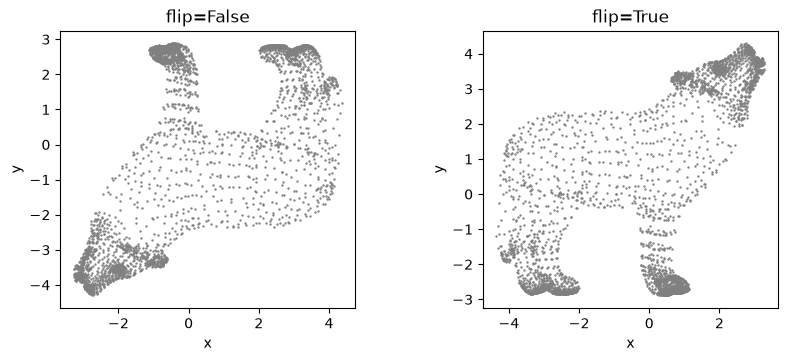

In [3]:
notFlipped = tools.loadobj(OBJ, flip=False)
flipped = tools.loadobj(OBJ, flip=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m, title in zip(axes, [notFlipped, flipped], ['flip=False', 'flip=True']):
    ax.scatter(m.vertices[:,0], m.vertices[:,1], s=0.5, c='gray')
    ax.set_aspect('equal'); ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y')
plt.show()

## 3. `Create_spehere`: build the geodesic sphere

Creates a geodesic sphere (frequency 3) as a trimesh mesh centered on the origin.

In [4]:
sphere = tools.Create_spehere()
radii = np.linalg.norm(sphere.vertices, axis=1)
print('vertices:', len(sphere.vertices), ' faces:', len(sphere.faces))
print('center:', np.round(sphere.vertices.mean(axis=0), 6))
print(f'radius: min={radii.min():.4f} max={radii.max():.4f}')
print('extents:', np.round(sphere.extents, 3))

vertices: 642  faces: 1280
center: [0. 0. 0.]
radius: min=1.0000 max=1.0000
extents: [2. 2. 2.]


## 4. `sliceSphere`: cut the sphere into a dome

Keeps the top half, above the ground plane at `groundY`. Each remaining vertex is a possible camera position, and repeated vertices along the cut are merged so no camera is used twice.

ground height: 0.0
sphere vertices: 642 -> dome vertices: 353
unique dome positions: 353
dome y range: [0. 1.]


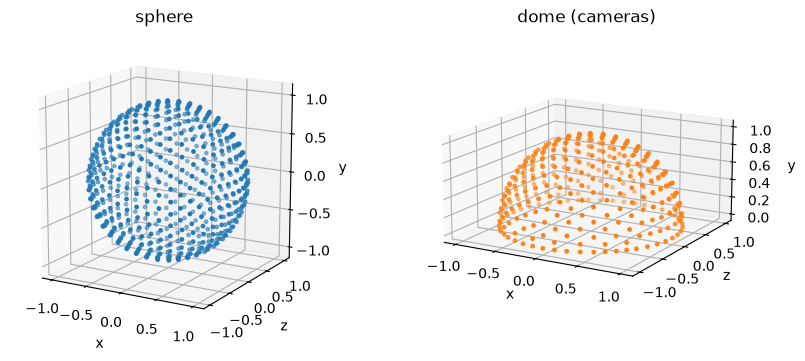

In [6]:
groundY = sphere.vertices.mean(axis=0)[1]
dome = tools.sliceSphere(sphere, groundY)

print('ground height:', round(float(groundY), 6))
print('sphere vertices:', len(sphere.vertices), '-> dome vertices:', len(dome.vertices))
print('unique dome positions:', len(np.unique(dome.vertices.round(5), axis=0)))
print('dome y range:', np.round([dome.vertices[:,1].min(), dome.vertices[:,1].max()], 3))

fig = plt.figure(figsize=(10, 4))
scatter3d(fig.add_subplot(121, projection='3d'), sphere.vertices, 'sphere', 'tab:blue', 6)
scatter3d(fig.add_subplot(122, projection='3d'), dome.vertices, 'dome (cameras)', 'tab:orange', 6)
plt.show()

## 5. `getCenterMass`, `scalObj`, `PlaceOnGround`: put the object under the dome

- `scalObj` scales the object so its longest side is half the sphere's diameter.
- `getCenterMass` finds the center of mass.
- `PlaceOnGround` centers the object horizontally on the dome and rests its lowest point on the ground.

In [7]:
mesh = tools.loadobj(OBJ, flip=FLIP)

def state(label):
    print(f'{label:18s} extents={np.round(mesh.extents, 3)}  center of mass={np.round(tools.getCenterMass(mesh), 3)}  lowest y={mesh.bounds[0][1]:.3f}')

state('loaded')
tools.scalObj(mesh, sphere)
state('after scalObj')
tools.PlaceOnGround(mesh, groundY, sphere.vertices.mean(axis=0))
state('after PlaceOnGround')

loaded             extents=[7.638 7.18  5.628]  center of mass=[-0.813  0.876 -0.143]  lowest y=-2.884
after scalObj      extents=[1.    0.94  0.737]  center of mass=[-0.106  0.115 -0.019]  lowest y=-0.378
after PlaceOnGround extents=[1.    0.94  0.737]  center of mass=[0.    0.492 0.   ]  lowest y=0.000


## 6. `convertToPyvista`: prepare the mesh for rendering

trimesh is used for the geometry and pyvista for rendering. pyvista stores each face as `[3, a, b, c]`.

In [8]:
pvMesh = tools.convertToPyvista(mesh)
print('type:', type(pvMesh).__name__)
print('points:', pvMesh.n_points, ' cells:', pvMesh.n_cells, ' all triangles:', pvMesh.is_all_triangles)
print('first two trimesh faces:', mesh.faces[:2].tolist())
print('first two pyvista faces:', pvMesh.faces[:8].tolist())

type: PolyData
points: 3889  cells: 7774  all triangles: True
first two trimesh faces: [[1796, 1797, 33], [1796, 2012, 1797]]
first two pyvista faces: [3, 1796, 1797, 33, 3, 1796, 2012, 1797]


## 7. `threeDobject` and `snapshotAndContour`: all of the above in one call

Creating a `snapshotAndContour` runs steps 1 to 6 through `addDomeOnObj`. `getMeshVert` and `getDomeVert` return the resulting vertices.

object name: wolf_alph3
mesh vertices: (3889, 3)  dome vertices: (353, 3)
same mesh as the manual steps: True


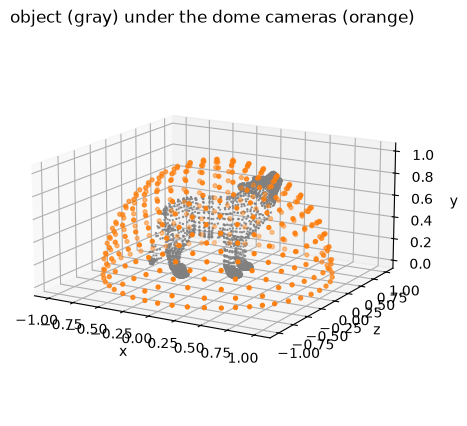

In [9]:
s = base.snapshotAndContour(OBJ, flip=FLIP)
meshVerts = s.getMeshVert(s.mesh)
domeVerts = s.getDomeVert(s.dome)

print('object name:', s.objname)
print('mesh vertices:', meshVerts.shape, ' dome vertices:', domeVerts.shape)
print('same mesh as the manual steps:', np.allclose(meshVerts, mesh.vertices))

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection='3d')
ax.scatter(meshVerts[:,0], meshVerts[:,2], meshVerts[:,1], s=0.5, c='gray')
ax.scatter(domeVerts[:,0], domeVerts[:,2], domeVerts[:,1], s=8, c='tab:orange')
ax.set_xlabel('x'); ax.set_ylabel('z'); ax.set_zlabel('y'); ax.set_box_aspect((2, 2, 1)); ax.view_init(elev=15, azim=-60)
ax.set_title('object (gray) under the dome cameras (orange)')
plt.show()

## 8. `getElevation` and `getAzimuth`: describe each camera

Each camera's angles are measured from the point on the ground directly under the object's center of mass. Below, one roughly side-on camera between 15° and 35° elevation is chosen to use in the next steps.

elevation range: [ 0. 90.]
azimuth range:   [-180.    175.24]
cameras from 0 to 85 degrees: 352 of 353
chosen camera 9: azimuth=121.72, elevation=18.00


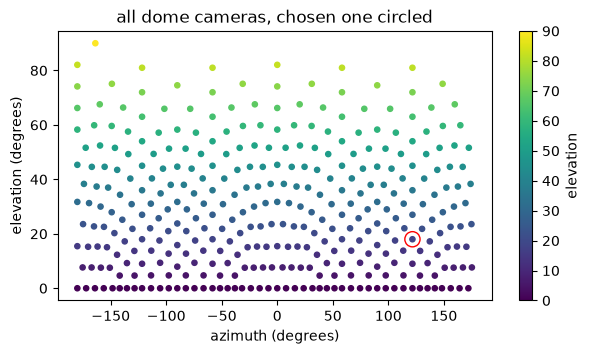

In [10]:
centerMass = s.getCenterMass(s.mesh)
refCenter = np.array([centerMass[0], domeVerts[:,1].min(), centerMass[2]])
elevations = np.array([s.getElevation(p, refCenter) for p in domeVerts])
azimuths = np.array([s.getAzimuth(p, refCenter) for p in domeVerts])

print('elevation range:', np.round([elevations.min(), elevations.max()], 2))
print('azimuth range:  ', np.round([azimuths.min(), azimuths.max()], 2))
print('cameras from 0 to 85 degrees:', int(((elevations >= 0) & (elevations <= 85)).sum()), 'of', len(domeVerts))

# side-on means the camera looks across the object's long horizontal axis
xz = meshVerts[:,[0,2]] - meshVerts[:,[0,2]].mean(axis=0)
longAxis = np.linalg.svd(xz, full_matrices=False)[2][0]
candidates = np.where((elevations >= 15) & (elevations <= 35))[0]
camIndex = min(candidates, key=lambda i: abs(domeVerts[i,[0,2]] @ longAxis) / np.linalg.norm(domeVerts[i,[0,2]]))
print(f'chosen camera {camIndex}: azimuth={azimuths[camIndex]:.2f}, elevation={elevations[camIndex]:.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
points = ax.scatter(azimuths, elevations, c=elevations, s=14, cmap='viridis')
ax.scatter(azimuths[camIndex], elevations[camIndex], s=120, facecolors='none', edgecolors='red')
ax.set_xlabel('azimuth (degrees)'); ax.set_ylabel('elevation (degrees)'); ax.set_title('all dome cameras, chosen one circled')
plt.colorbar(points, label='elevation'); plt.show()

## 9. `fitObjToCamera`: fit the object in the frame, then take the snapshot

This uses the same camera setup as `snapshots()`. `fitObjToCamera` sets the zoom so the object fits the image without changing its coordinates.

zoom (parallel_scale) before: 0.7789
zoom (parallel_scale) after:  0.5587
image shape: (600, 800, 3)


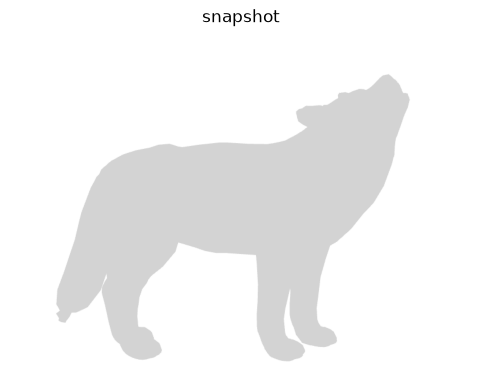

In [11]:
plotter = pv.Plotter(off_screen=True, window_size=(800, 600))
plotter.add_mesh(s.obj, color='lightgray', lighting=False, show_edges=False)
plotter.camera.enable_parallel_projection()

camPos = domeVerts[camIndex]
plotter.camera.position = camPos
plotter.camera.focal_point = centerMass
plotter.camera.up = np.array([0, 1, 0])

print('zoom (parallel_scale) before:', round(plotter.camera.parallel_scale, 4))
s.fitObjToCamera(plotter, s.obj)
print('zoom (parallel_scale) after: ', round(plotter.camera.parallel_scale, 4))

snapshotFile = 'sample_snapshot.png'
plotter.show(screenshot=snapshotFile, auto_close=False)
plotter.close()

image = cv.imread(snapshotFile)
print('image shape:', image.shape)
plt.figure(figsize=(6, 4.5)); plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB)); plt.axis('off'); plt.title('snapshot'); plt.show()

## 10. `takecontour`: find the outline

`takecontour` reads the image as grayscale, inverts it, marks every non-background pixel, and keeps the largest outer contour. The first three panels repeat its internal steps so they can be seen, and the last shows what the function actually returned.

contour shape: (2427, 1, 2) (points, 1, x and y)
contour area in pixels: 145095.5
bounding box (x, y, width, height): (80, 75, 613, 498)


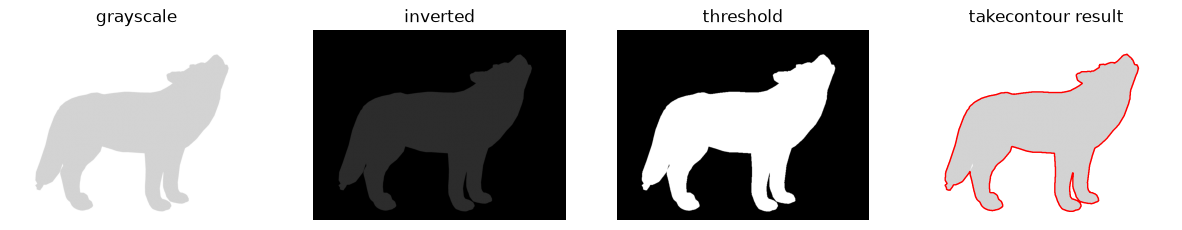

In [12]:
gray = cv.imread(snapshotFile, cv.IMREAD_GRAYSCALE)
inverted = cv.bitwise_not(gray)
_, thresh = cv.threshold(inverted, 0, 255, cv.THRESH_BINARY)

contour = s.takecontour(snapshotFile)
print('contour shape:', contour.shape, '(points, 1, x and y)')
print('contour area in pixels:', cv.contourArea(contour))
print('bounding box (x, y, width, height):', cv.boundingRect(contour))

outline = contour.reshape(-1, 2)
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, im, title in zip(axes, [gray, inverted, thresh], ['grayscale', 'inverted', 'threshold']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(title); ax.axis('off')
axes[3].imshow(gray, cmap='gray', vmin=0, vmax=255); axes[3].plot(outline[:,0], outline[:,1], 'r', lw=1)
axes[3].set_title('takecontour result'); axes[3].axis('off')
plt.show()

## 11. `get2dCenterMass` and `findStartingPoint`: choose where the contour starts

`get2dCenterMass` finds the center of the outline. `findStartingPoint` picks the point straight below that center, so every contour starts from a consistent place.

2D center: [392, 320]
starting index: 1393  starting point: [392, 386]


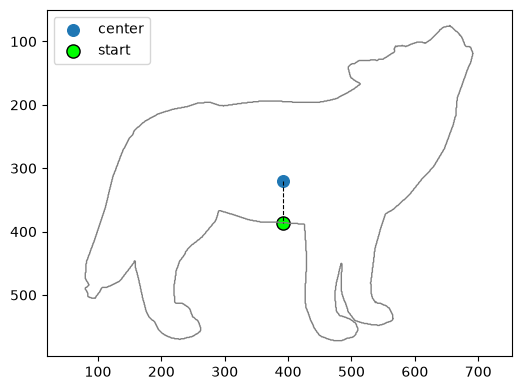

In [13]:
contourCenter = s.get2dCenterMass(contour)
startIndex = s.findStartingPoint(contour, contourCenter)
startPoint = outline[startIndex]

print('2D center:', contourCenter)
print('starting index:', int(startIndex), ' starting point:', startPoint.tolist())

plt.figure(figsize=(6, 4.5)); plt.plot(outline[:,0], outline[:,1], color='gray', lw=1)
plt.scatter(*contourCenter, c='tab:blue', s=70, label='center')
plt.scatter(*startPoint, c='lime', edgecolors='black', s=90, label='start')
plt.plot([contourCenter[0], startPoint[0]], [contourCenter[1], startPoint[1]], 'k--', lw=0.8)
plt.gca().invert_yaxis(); plt.axis('equal'); plt.legend(); plt.show()

## 12. `equalSpacedPoints`: resample to 120 points

The outline has a different number of pixels in every view. This step rebuilds it as exactly 120 points, evenly spaced along its length, beginning at the starting point.

points before: 2427 -> after: 120
first point: [392.0, 386.0] (the starting point)
gap between neighbouring points: mean=21.10, min=4.64, max=23.08 pixels


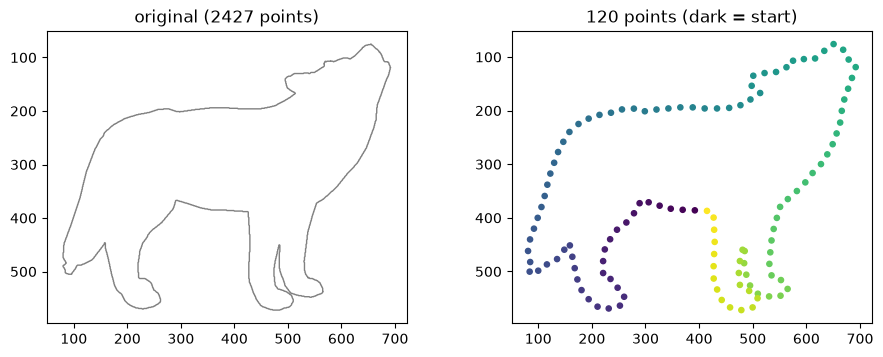

In [14]:
spaced = s.equalSpacedPoints(contour, startIndex)
gaps = np.linalg.norm(np.diff(spaced, axis=0), axis=1)

print('points before:', len(outline), '-> after:', len(spaced))
print('first point:', spaced[0].tolist(), '(the starting point)')
print(f'gap between neighbouring points: mean={gaps.mean():.2f}, min={gaps.min():.2f}, max={gaps.max():.2f} pixels')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(outline[:,0], outline[:,1], color='gray', lw=1); axes[0].set_title(f'original ({len(outline)} points)')
axes[1].scatter(spaced[:,0], spaced[:,1], c=np.arange(len(spaced)), cmap='viridis', s=14); axes[1].set_title('120 points (dark = start)')
for ax in axes: ax.invert_yaxis(); ax.set_aspect('equal')
plt.show()

## 13. `normalizepts`: remove position and size

Shifts the contour so its minimum x and y are 0, then divides by the standard deviation of the points' distances from the origin. This makes contours comparable whatever their size in the image.

before: min [81. 76.]  max [691.95 572.  ]
after:  min [0. 0.]  max [4.65 3.77]
std of distance from origin: 1.0
shape: (120, 2)


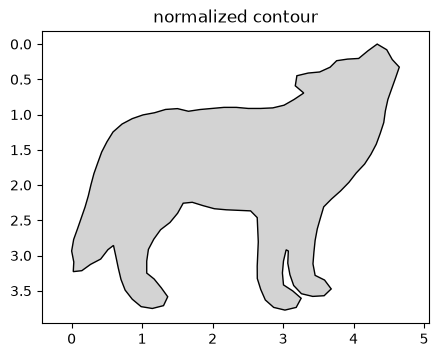

In [15]:
normalizedPts = s.normalizepts(spaced)
distances = np.linalg.norm(normalizedPts, axis=1)

print('before: min', np.round(spaced.min(axis=0), 2), ' max', np.round(spaced.max(axis=0), 2))
print('after:  min', np.round(normalizedPts.min(axis=0), 2), ' max', np.round(normalizedPts.max(axis=0), 2))
print('std of distance from origin:', round(float(distances.std()), 4))
print('shape:', normalizedPts.shape)

plt.figure(figsize=(5, 3.8)); plt.fill(normalizedPts[:,0], normalizedPts[:,1], color='lightgray', edgecolor='black')
plt.gca().invert_yaxis(); plt.axis('equal'); plt.title('normalized contour'); plt.show()

## 14. `snapshots`: run steps 8 to 13 for every camera

This is the same range `main.py` uses, 0 to 85 degrees. The result is an array of shape (views, 120, 2) and one information record per view.

processing object
taking contours....
contours shape: (352, 120, 2)
records: 352
first record: {'camViewNum': 0, 'name': 'wolf_alph3', 'azimuth': -180.0, 'elevation': 58.282525588538995}


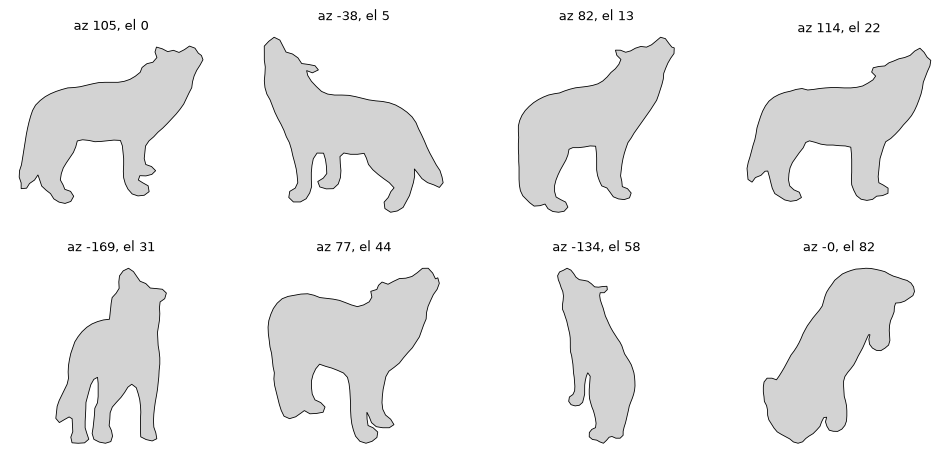

In [16]:
contours, contoursData = s.snapshots(0, 85)
print('contours shape:', contours.shape)
print('records:', len(contoursData))
print('first record:', contoursData[0])

order = np.argsort([d['elevation'] for d in contoursData])
picks = order[np.linspace(0, len(order) - 1, 8).astype(int)]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
for ax, i in zip(axes.ravel(), picks):
    ax.fill(contours[i][:,0], contours[i][:,1], color='lightgray', edgecolor='black', lw=0.6)
    ax.invert_yaxis(); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f"az {contoursData[i]['azimuth']:.0f}, el {contoursData[i]['elevation']:.0f}", fontsize=9)
plt.show()

## 15. `saveJson`: save the results

Everything here is written to the temporary folder. The second call shows that `saveJson` **adds to** existing files, so running the same object twice stores it twice.

In [16]:
camFile, contourFile = 'demo_camData.json', 'demo_contourData.json'

def fileCounts():
    with open(camFile) as f: cam = json.load(f)['camData']
    with open(contourFile) as f: pts = json.load(f)['contoursPts']
    return cam, pts

s.saveJson(camFile, contourFile, [dict(d) for d in contoursData], contours)
cam, pts = fileCounts()
print('after first save: ', len(cam), 'camera records,', len(pts), 'contours')
print('record 0:', cam[0])
print('contour 0 shape:', np.array(pts[0]).shape)

s.saveJson(camFile, contourFile, [dict(d) for d in contoursData], contours)
cam, pts = fileCounts()
print('after second save:', len(cam), 'camera records,', len(pts), 'contours')
print('last index:', cam[-1]['index'])

after first save:  352 camera records, 352 contours
record 0: {'camViewNum': 0, 'name': 'wolf_alph3', 'azimuth': -180.0, 'elevation': 58.282525588538995, 'index': 0}
contour 0 shape: (120, 2)
after second save: 704 camera records, 704 contours
last index: 703


## 16. `contourVisualizer`: draw a contour and save the image

`drawPoints` colors the points from green at the start, through blue, to red at the end. `savefig` writes the image to a folder, and it's loaded back here to show the saved file.

saved files: ['demo_contour.png']  image shape: (790, 1105, 4)


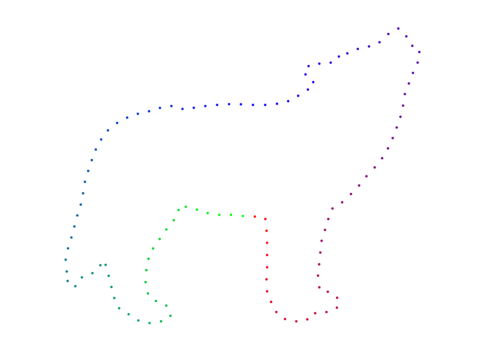

In [17]:
visualize = base.contourVisualizer()
visualize.drawPoints(contours[picks[3]])
visualize.savefig('demo_contour.png', folder='demo_output')
plt.close('all')  # drawPoints leaves one extra blank figure open

savedImage = plt.imread('demo_output/demo_contour.png')
print('saved files:', os.listdir('demo_output'), ' image shape:', savedImage.shape)
plt.figure(figsize=(6, 4.5)); plt.imshow(savedImage); plt.axis('off'); plt.show()

In [18]:
# remove the temporary files and return to the project folder
os.chdir(PROJECT)
shutil.rmtree(WORK)
print('temporary files removed')

temporary files removed
